## IMPORTING PACKAGES:

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

## DATASET:

In [59]:
df = pd.read_csv("train.csv").drop(columns='id')
df.head()

,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,NaN,40.0,64173
1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357
2,SpiceJet,SG-8107,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251
3,NaN,0.00E+00,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0,1776
4,Air_India,AI-569,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0,3584


In [58]:
#looks 'flight' feature has some issues regarding the numbers entered. May drop during preprocessing.

# IDENTIFY DATATYPES OF DIFFERENT COLUMNS:

In [66]:
print(df.info())
print(df.columns.to_list())

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   airline      35387 non-null  str    
 1   flight       40000 non-null  str    
 2   source       40000 non-null  str    
 3   departure    35208 non-null  str    
 4   stops        37681 non-null  str    
 5   arrival      40000 non-null  str    
 6   destination  40000 non-null  str    
 7   class        40000 non-null  str    
 8   duration     36987 non-null  float64
 9   days_left    35562 non-null  float64
 10  price        40000 non-null  int64  
dtypes: float64(2), int64(1), str(8)
memory usage: 3.4 MB
None
['airline', 'flight', 'source', 'departure', 'stops', 'arrival', 'destination', 'class', 'duration', 'days_left', 'price']


# DESCRIPTIVE STATISTICS:

In [54]:
df.describe()

,id,duration,days_left,price
count,40000.00000,36987.000000,35562.000000,40000.00000
mean,19999.50000,12.004088,26.197936,20801.49025
std,11547.14972,7.108063,13.469232,22729.14842
min,0.00000,0.830000,1.000000,1105.00000
25%,9999.75000,6.670000,15.000000,4687.00000
50%,19999.50000,11.080000,26.000000,7353.00000
75%,29999.25000,15.920000,38.000000,42521.00000
max,39999.00000,47.080000,49.000000,114704.00000


In [55]:
df[(df['airline']=='Indigo')&(df["flight"].str.startswith(("6.00E")))].shape[0]

573

In [68]:
print(f"no. of rows with Indigo's corrupted 'flight' cell: {df[df['flight'].str.startswith(("6.00E"))].shape[0]}")
print(f"no. of rows with 0.00E in corrupted 'flight' cell: {df[df["flight"].str.startswith("0.00E")].shape[0]}")

no. of rows with Indigo's corrupted 'flight' cell: 652
no. of rows with 0.00E in corrupted 'flight' cell: 5270


In [41]:
mask = df['flight'].str.startswith("6.00E") & (df['airline'] != 'Indigo')
df.loc[mask, 'airline'].value_counts(dropna=False)

airline
NaN    79
Name: count, dtype: int64

# HANDLING MISSING VALUES:

In [14]:
df.isna().sum() #counting the NaN's

id                0
airline        4613
flight            0
source            0
departure      4792
stops          2319
arrival           0
destination       0
class             0
duration       3013
days_left      4438
price             0
dtype: int64

'flight' column has some corrupted values, mainly observed for Indigo, since Indigo's code is 6E which may have not rendered corrected in csv format.

steps taken to rectify:
- filtering out the 6.00E/0.00E corrupted values in flight
- filling those with missing airline with 'Indigo'

# HANDLING DUPLICATES:

# HANDLING OUTLIERS:

# VISUALIZATIONS:

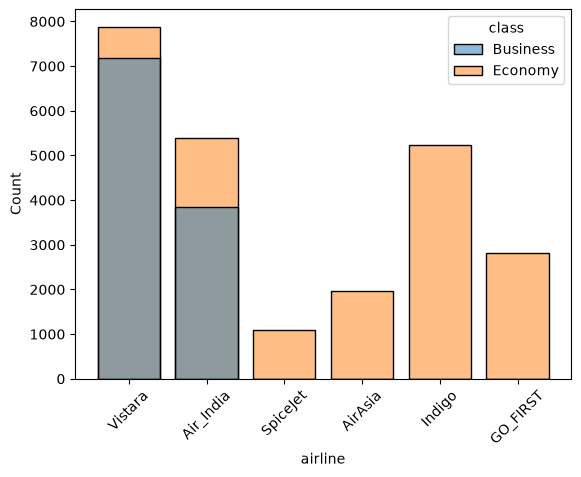

In [53]:
sns.histplot(data=df, x='airline', shrink=0.8,hue='class')
plt.xticks(rotation=45)
plt.show()

# SCALING AND ENCODING:

# MODEL BUILDING:

# HYPERPARAMETER TUNING:

# COMPARISONS: